# Data loading and quality control

In [9]:
import numpy as np
import pandas as pd
import scipy.io
import scipy.sparse
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

#sample_id = "846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1"
#sample_id = "846531_HD_BA_WM_C_DNB_SM_J74_3_A1"
#sample_id = "846531_HD_BA_WM_C_DNB_SM_J75_3_D1_GFP_R1"
sample_id = "846531_HD_BA_WM_C_DNB_SM_D90_7_D1_GFP_R1"
#base = f"/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_D90-5-A1-GFP_R1/outs/binned_outputs/square_008um/"
#base = f"/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_J74-3-A1-GFP_R1/outs/binned_outputs/square_008um/"
#base = f"/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_J75-3-D1-GFP_R1/outs/binned_outputs/square_008um/"
base = f"/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_D90-7-D1-GFP_R1/outs/binned_outputs/square_008um/"

mtx_dir = f"{base}/raw_feature_bc_matrix/"
spatial_dir = f"{base}/spatial/"

# Load tissue positions 
M = scipy.io.mmread(f"{mtx_dir}/matrix.mtx.gz").tocsc()
barcodes = pd.read_csv(f"{mtx_dir}/barcodes.tsv.gz", header=None)[0].values
features = pd.read_csv(f"{mtx_dir}/features.tsv.gz", header=None, sep="\t")

# Load tissue positions 
pos = pd.read_csv(
    f"{spatial_dir}/tissue_positions.csv",
    header=None,
    names=["barcode", "in_tissue", "array_row", "array_col",
           "pxl_row_in_fullres", "pxl_col_in_fullres"]
)

gene_names = features[1].values  # column 2 = gene name

print(f"Raw matrix: {M.shape[0]} genes x {M.shape[1]} spots")

# Collapse duplicate gene names by summing rows
unique_genes, inverse = np.unique(gene_names, return_inverse=True)
n_unique = len(unique_genes)
n_spots  = M.shape[1]

# Build a (n_unique x n_original) summation matrix and multiply
agg = scipy.sparse.csr_matrix(
    (np.ones(len(inverse)), (inverse, np.arange(len(inverse)))),
    shape=(n_unique, len(gene_names))
)
M = (agg @ M).tocsc()

print(f"After collapsing duplicates: {M.shape[0]} genes x {M.shape[1]} spots")

pos = pos[pos["in_tissue"] == 1].set_index("barcode")

# Subset to in-tissue barcodes, preserving column order
keep = [i for i, b in enumerate(barcodes) if b in pos.index]
barcodes_tissue = barcodes[keep]
M = M[:, keep]
pos = pos.loc[barcodes_tissue]

print(f"Final matrix: {M.shape[0]} genes x {M.shape[1]} spots")


/lsf_tmp/305572954.tmpdir/ipykernel_1741756/2928131938.py:29: DtypeWarning: Columns (1,2,3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  pos = pd.read_csv(


Raw matrix: 32286 genes x 700751 spots
After collapsing duplicates: 32246 genes x 700751 spots
Final matrix: 32246 genes x 488889 spots


# per-spot QC metrics

/lsf_tmp/305572954.tmpdir/ipykernel_1741756/2121070111.py:14: RuntimeWarning: invalid value encountered in divide
  np.array(M[mt_idx, :].sum(axis=0)).flatten() / nUMI * 100,


Total spots:       488889
Total genes:       32246
Mean nUMI:         444.8
Median nUMI:       382.0
Mean nGene:        388.0
Median nGene:      347.0
Matrix sparsity:   0.988
       nUMI   nGene     pct_MT
min     0.0     0.0   0.000000
25%   245.0   226.0   1.318681
50%   382.0   347.0   1.915709
75%   566.0   502.0   2.658487
max  5160.0  2987.0  50.000000


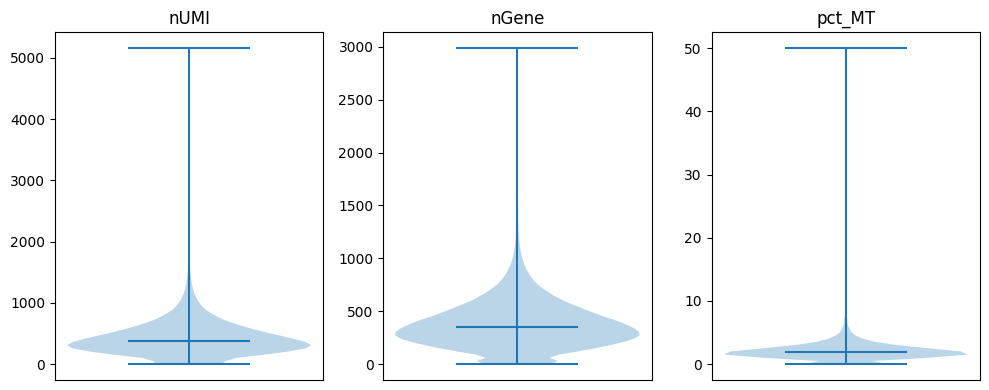

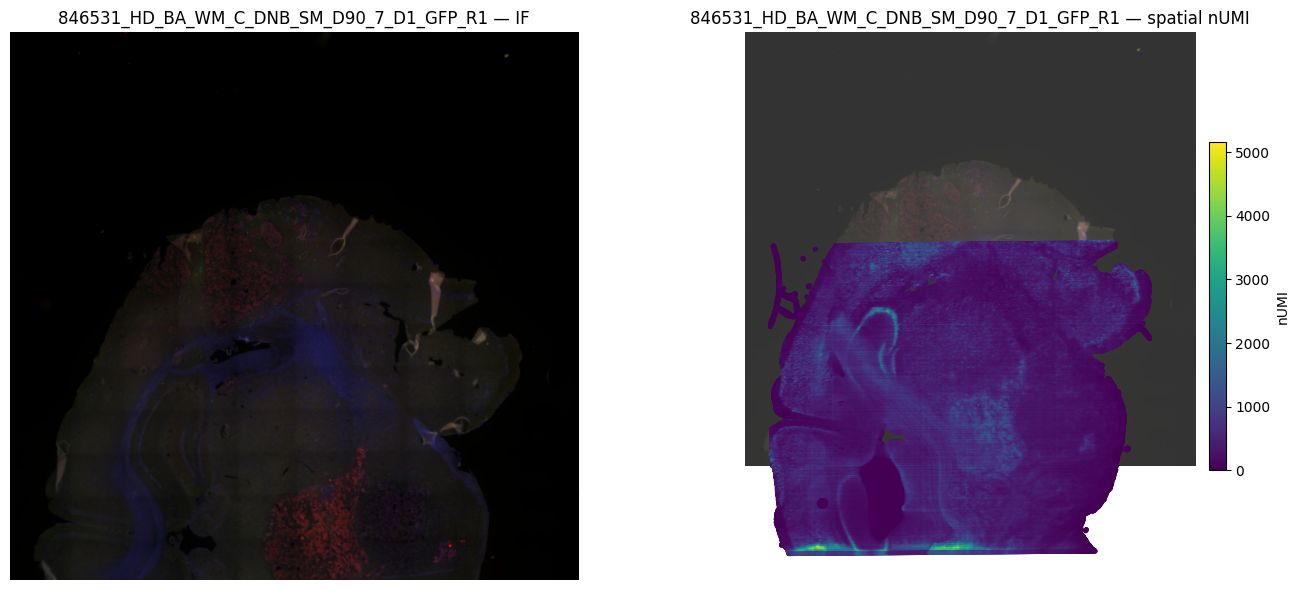

In [10]:
import numpy as np
import pandas as pd
import json
import scipy.sparse
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# ── QC metrics ──────────────────────────────────────────────────────────────

nUMI   = np.array(M.sum(axis=0)).flatten()
nGene  = np.array((M > 0).sum(axis=0)).flatten()
mt_idx = np.array([g.startswith("mt-") for g in unique_genes])
pct_MT = np.where(nUMI > 0, 
                  np.array(M[mt_idx, :].sum(axis=0)).flatten() / nUMI * 100, 
                  0)
metadata = pd.DataFrame({"nUMI": nUMI, "nGene": nGene, "pct_MT": pct_MT},
                         index=barcodes_tissue)

# Sample-level summary
n_spots        = M.shape[1]
n_genes        = M.shape[0]
sparsity       = 1 - M.nnz / (n_spots * n_genes)

print(f"Total spots:       {n_spots}")
print(f"Total genes:       {n_genes}")
print(f"Mean nUMI:         {nUMI.mean():.1f}")
print(f"Median nUMI:       {np.median(nUMI):.1f}")
print(f"Mean nGene:        {nGene.mean():.1f}")
print(f"Median nGene:      {np.median(nGene):.1f}")
print(f"Matrix sparsity:   {sparsity:.3f}")

print(metadata.describe(percentiles=[0.25, 0.5, 0.75])
             .loc[["min", "25%", "50%", "75%", "max"]])

# ── Violin plots ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, col in zip(axes, ["nUMI", "nGene", "pct_MT"]):
    ax.violinplot(metadata[col], showmedians=True)
    ax.set_title(col)
    ax.set_xticks([])
plt.tight_layout()
plt.savefig(base + "QC_counts_spots_" + sample_id + ".png")

plt.show()

# ── Spatial QC maps ───────────────────────────────────────────────────────────

scalef    = json.load(open(f"{spatial_dir}/scalefactors_json.json"))
lowres_sf = scalef["tissue_lowres_scalef"]
img       = mpimg.imread(f"{spatial_dir}/tissue_lowres_image.png")

x = pos["pxl_col_in_fullres"].values * lowres_sf
y = pos["pxl_row_in_fullres"].values * lowres_sf

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(img, origin="upper")
axes[0].axis("off")
axes[0].set_title(f"{sample_id} — IF")

axes[1].imshow(img, origin="upper", alpha=0.8)
sc = axes[1].scatter(x, y, c=metadata["nUMI"].values, cmap="viridis", s=10, linewidths=0)
axes[1].axis("off")
axes[1].set_title(f"{sample_id} — spatial nUMI")

# Add colorbar on a separate axis so it doesn't shrink the right panel
fig.colorbar(sc, ax=axes[1], label="nUMI", shrink=0.6, pad=0.02)

plt.tight_layout()
plt.savefig(base + "QC_counts_spots_" + sample_id + "_v2.png")
plt.show()


# Part I-B: Data Object Construction

In [3]:
sample_id = "846531_HD_BA_WM_C_DNB_SM_J74_3_A1"
base = f"/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_J74-3-A1-GFP_R1/outs/binned_outputs/square_008um/"

mtx_dir = f"{base}/raw_feature_bc_matrix/"
spatial_dir = f"{base}/spatial/"

pos = pd.read_csv(
        f"{spatial_dir}/tissue_positions.csv",
        header=None,
        names=["barcode", "in_tissue", "array_row", "array_col",
               "pxl_row_in_fullres", "pxl_col_in_fullres"]
    )
pos = pos[pos["in_tissue"] == 1].set_index("barcode")

#M = scipy.io.mmread(open(f"{mtx_dir}/matrix.mtx.gz", "rb")).tocsc()

nUMI = np.array(M.sum(axis=0)).flatten()
nGene = np.array((M > 0).sum(axis=0)).flatten()
mt_idx = np.array([g.startswith("mt-") for g in unique_genes])
pct_MT = np.where(nUMI > 0,
            np.array(M[mt_idx, :].sum(axis=0)).flatten() / nUMI * 100,
            0)

/lsf_tmp/305214243.tmpdir/ipykernel_3086035/1366664241.py:7: DtypeWarning: Columns (1,2,3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  pos = pd.read_csv(
/lsf_tmp/305214243.tmpdir/ipykernel_3086035/1366664241.py:21: RuntimeWarning: invalid value encountered in divide
  np.array(M[mt_idx, :].sum(axis=0)).flatten() / nUMI * 100,


In [ ]:
import numpy as np
import pandas as pd
import scipy.io
import scipy.sparse
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import anndata
from mpl_toolkits.axes_grid1 import make_axes_locatable

sample_id = "846531_HD_BA_WM_C_DNB_SM_J74_3_A1"
base = f"/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_J74-3-A1-GFP_R1/outs/binned_outputs/square_008um/"

mtx_dir = f"{base}/raw_feature_bc_matrix/"
spatial_dir = f"{base}/spatial/"


def load_sample(sample_id,base):
    #mtx_dir = f"{base}/raw_feature_bc_matrix/"
    mtx_dir = f"{base}/filtered_feature_bc_matrix/"
    
    spatial_dir = f"{base}/spatial/"

    M = scipy.io.mmread(open(f"{mtx_dir}/matrix.mtx.gz", "rb")).tocsc()
    barcodes = pd.read_csv(open(f"{mtx_dir}/barcodes.tsv.gz"), header=None)[0].values
    features = pd.read_csv(open(f"{mtx_dir}/features.tsv.gz"), header=None, sep="\t")
    gene_names = features[0].values

    unique_genes, inverse = np.unique(gene_names, return_inverse=True)
    agg = scipy.sparse.csr_matrix(
        (np.ones(len(inverse)), (inverse, np.arange(len(inverse)))),
        shape=(len(unique_genes), len(gene_names))
    )

    agg = agg.T
    
    #print("M shape:", M.shape)
    M = (agg @ M).tocsc()

    pos = pd.read_csv(
        f"{spatial_dir}/tissue_positions.csv",
        header=None,
        names=["barcode", "in_tissue", "array_row", "array_col",
               "pxl_row_in_fullres", "pxl_col_in_fullres"]
    )
    pos = pos[pos["in_tissue"] == 1].set_index("barcode")

    pos_set = set(pos.index)
    keep = np.where(np.array([b in pos_set for b in barcodes]))[0]
    
    barcodes_tissue = barcodes[keep]
    M = M[:, keep]
    pos = pos.loc[barcodes_tissue]

    nUMI = np.array(M.sum(axis=0)).flatten()
    nGene = np.array((M > 0).sum(axis=0)).flatten()
    mt_idx = np.array([g.startswith("mt-") for g in unique_genes])
    pct_MT = np.where(nUMI > 0,
                      np.array(M[mt_idx, :].sum(axis=0)).flatten() / nUMI * 100,
                      0)

    scalef = json.load(open(f"{spatial_dir}/scalefactors_json.json"))
    img = mpimg.imread(f"{spatial_dir}/tissue_lowres_image.png")

    # Load pathology annotations — index matches original barcodes exactly
    #meta = pd.read_csv(f"{base}/metadata/{sample_id}_metadata.csv", index_col=0)

    adata = anndata.AnnData(
        X = M.T.tocsr(),
        obs = pd.DataFrame({
            "sample_id": sample_id,
            "nUMI": nUMI,
            "nGene": nGene,
            "pct_MT": pct_MT #"Classification": meta.loc[barcodes_tissue, "Classification"].values
        }, index=barcodes_tissue),
        var = pd.DataFrame(index=unique_genes)
    )

    #adata.obs["Classification"] = adata.obs["Classification"].astype("category")
    adata.obsm["spatial"] = pos[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values
    adata.uns["spatial"] = {
        sample_id: {
            "images": {"lowres": img},
            "scalefactors": scalef
        }
    }

    return adata

# ── Load samples ──────────────────────────────────────────────────────────────
sample_1 = "846531_HD_BA_WM_C_DNB_SM_J74_3_A1"
base_1 = f"/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_J74-3-A1-GFP_R1/outs/binned_outputs/square_008um/"
adata = load_sample(sample_1,base_1)





In [ ]:
"""
Instrumented debug script for kernel-death investigation (session a15697).
Run this instead of your notebook cell. Logs are written to:
  /Users/demerson/.cursor/debug-logs/debug-a15697.log
"""
import json
import os
import resource
import time

LOG_PATH = "/Users/demerson/.cursor/debug-logs/debug-a15697.log"
SESSION_ID = "a15697"
RUN_ID = "pre-fix"


def _dbg(hypothesis_id, location, message, data=None):
    # #region agent log
    entry = { 
        "sessionId": SESSION_ID,
        "runId": RUN_ID,
        "hypothesisId": hypothesis_id,
        "location": location,
        "message": message,
        "data": data or {}, 
        "timestamp": int(time.time() * 1000),
    }   
    with open(LOG_PATH, "a") as f:
        f.write(json.dumps(entry) + "\n")
    # #endregion


def _mem_mb():
    ru = resource.getrusage(resource.RUSAGE_SELF)
    return round(ru.ru_maxrss / (1024 * 1024), 1)

def _sparse_stats(m, name):
    return {
        "name": name,
        "shape": list(m.shape),
        "nnz": int(m.nnz),
        "dtype": str(m.dtype),
        "format": m.getformat(),
        "mem_mb": _mem_mb(),
    }   


import numpy as np
import pandas as pd
import scipy.io
import scipy.sparse
import matplotlib.image as mpimg
import anndata

_dbg("H0", "debug_load_sample_a15697.py:start", "script started", {"mem_mb": _mem_mb()})

def load_sample(sample_id, base):
    _dbg("H1", "load_sample:entry", "load_sample called", {"sample_id": sample_id, "base": base, "mem_mb": _mem_mb()})

    mtx_dir = f"{base}/raw_feature_bc_matrix/"
    spatial_dir = f"{base}/spatial/"

    mtx_path = f"{mtx_dir}/matrix.mtx.gz"
    mtx_size_gb = round(os.path.getsize(mtx_path) / (1024 ** 3), 3)
    _dbg("H1", "load_sample:before_mmread", "about to mmread matrix", {"mtx_size_gb": mtx_size_gb, "mem_mb": _mem_mb()})

    M = scipy.io.mmread(open(mtx_path, "rb")).tocsc()
    _dbg("H1", "load_sample:after_mmread", "matrix loaded", _sparse_stats(M, "M_raw"))

    barcodes = pd.read_csv(open(f"{mtx_dir}/barcodes.tsv.gz"), header=None)[0].values
    features = pd.read_csv(open(f"{mtx_dir}/features.tsv.gz"), header=None, sep="\t")
    gene_names = features[0].values

    _dbg("H2", "load_sample:after_metadata", "barcodes/features loaded", {
        "n_barcodes": len(barcodes),
        "n_features": len(gene_names),
        "n_unique_genes": len(np.unique(gene_names)),
        "mem_mb": _mem_mb(),
    })

    unique_genes, inverse = np.unique(gene_names, return_inverse=True)
    agg = scipy.sparse.csr_matrix(
        (np.ones(len(inverse)), (inverse, np.arange(len(inverse)))),
        shape=(len(unique_genes), len(gene_names)),
    )
    agg = agg.T

    _dbg("H2", "load_sample:before_agg_matmul", "about to aggregate genes", {
        "agg_shape": list(agg.shape),
        "M_shape": list(M.shape),
        "agg_nnz": int(agg.nnz),
        "mem_mb": _mem_mb(),
    })

    M = (agg @ M).tocsc()
    _dbg("H2", "load_sample:after_agg_matmul", "gene aggregation done", _sparse_stats(M, "M_agg"))

    pos = pd.read_csv(
        f"{spatial_dir}/tissue_positions.csv",
        header=None,
        names=["barcode", "in_tissue", "array_row", "array_col", "pxl_row_in_fullres", "pxl_col_in_fullres"],
    )
    pos = pos[pos["in_tissue"] == 1].set_index("barcode")
    pos_set = set(pos.index)

    _dbg("H3", "load_sample:before_barcode_filter", "about to filter barcodes", {
        "n_pos_in_tissue": len(pos),
        "n_barcodes": len(barcodes),
        "mem_mb": _mem_mb(),
    })

    keep = np.where(np.array([b in pos_set for b in barcodes]))[0]
    barcodes_tissue = barcodes[keep]
    M = M[:, keep]
    pos = pos.loc[barcodes_tissue]

    _dbg("H3", "load_sample:after_barcode_filter", "barcode filter done", {
        "n_keep": len(keep),
        "M_shape": list(M.shape),
        "M_nnz": int(M.nnz),
        "mem_mb": _mem_mb(),
    })

    nUMI = np.array(M.sum(axis=0)).flatten()
    nGene = np.array((M > 0).sum(axis=0)).flatten()
    mt_idx = np.array([g.startswith("mt-") for g in unique_genes])
    pct_MT = np.where(
        nUMI > 0,
        np.array(M[mt_idx, :].sum(axis=0)).flatten() / nUMI * 100,
        0,
    )

    _dbg("H4", "load_sample:after_qc_metrics", "QC metrics computed", {"mem_mb": _mem_mb()})

    scalef = json.load(open(f"{spatial_dir}/scalefactors_json.json"))
    img = mpimg.imread(f"{spatial_dir}/tissue_lowres_image.png")

    _dbg("H5", "load_sample:after_image_load", "image loaded", {
        "img_shape": list(img.shape),
        "img_dtype": str(img.dtype),
        "img_nbytes_mb": round(img.nbytes / (1024 ** 2), 1),
        "mem_mb": _mem_mb(),

    _dbg("H4", "load_sample:before_transpose", "about to M.T.tocsr()", _sparse_stats(M, "M_before_T"))

    X = M.T.tocsr()
    _dbg("H4", "load_sample:after_transpose", "transpose done", _sparse_stats(X, "X"))

    adata = anndata.AnnData(
        X=X,
        obs=pd.DataFrame(
            {
                "sample_id": sample_id,
                "nUMI": nUMI,
                "nGene": nGene,
                "pct_MT": pct_MT,
            },
            index=barcodes_tissue,
        ),
        var=pd.DataFrame(index=unique_genes),
    )
    adata.obsm["spatial"] = pos[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values
    adata.uns["spatial"] = {sample_id: {"images": {"lowres": img}, "scalefactors": scalef}}

    _dbg("H5", "load_sample:complete", "AnnData built successfully", {
        "adata_shape": list(adata.shape),
        "mem_mb": _mem_mb(),
    })

    return adata

# ── Load samples ──────────────────────────────────────────────────────────────
sample_1 = "846531_HD_BA_WM_C_DNB_SM_J74_3_A1"
base_1 = f"/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_J74-3-A1-GFP_R1/outs/binned_outputs/square_008um/"
adata = load_sample(sample_1,base_1)


In [5]:
adata.uns["spatial"][sample_id]["scalefactors"]["tissue_lowres_scalef"]

0.051369864

AnnData object with n_obs × n_vars = 409470 × 32246
    obs: 'sample_id', 'nUMI', 'nGene', 'pct_MT'
    uns: 'spatial'
    obsm: 'spatial'
                                               sample_id   nUMI  nGene  \
s_008um_00156_00681-1  846531_HD_BA_WM_C_DNB_SM_J74_3_A1  113.0    111   
s_008um_00156_00682-1  846531_HD_BA_WM_C_DNB_SM_J74_3_A1  141.0    135   
s_008um_00156_00683-1  846531_HD_BA_WM_C_DNB_SM_J74_3_A1  211.0    205   
s_008um_00156_00684-1  846531_HD_BA_WM_C_DNB_SM_J74_3_A1  269.0    256   
s_008um_00156_00685-1  846531_HD_BA_WM_C_DNB_SM_J74_3_A1  344.0    318   

                         pct_MT  
s_008um_00156_00681-1  3.539823  
s_008um_00156_00682-1  0.709220  
s_008um_00156_00683-1  1.895735  
s_008um_00156_00684-1  3.345725  
s_008um_00156_00685-1  1.744186  
       nUMI   nGene      pct_MT
min     0.0     0.0    0.000000
25%   414.0   375.0    1.257862
50%   726.0   627.0    1.714286
75%  1136.0   924.0    2.362205
max  5688.0  3092.0  100.000000



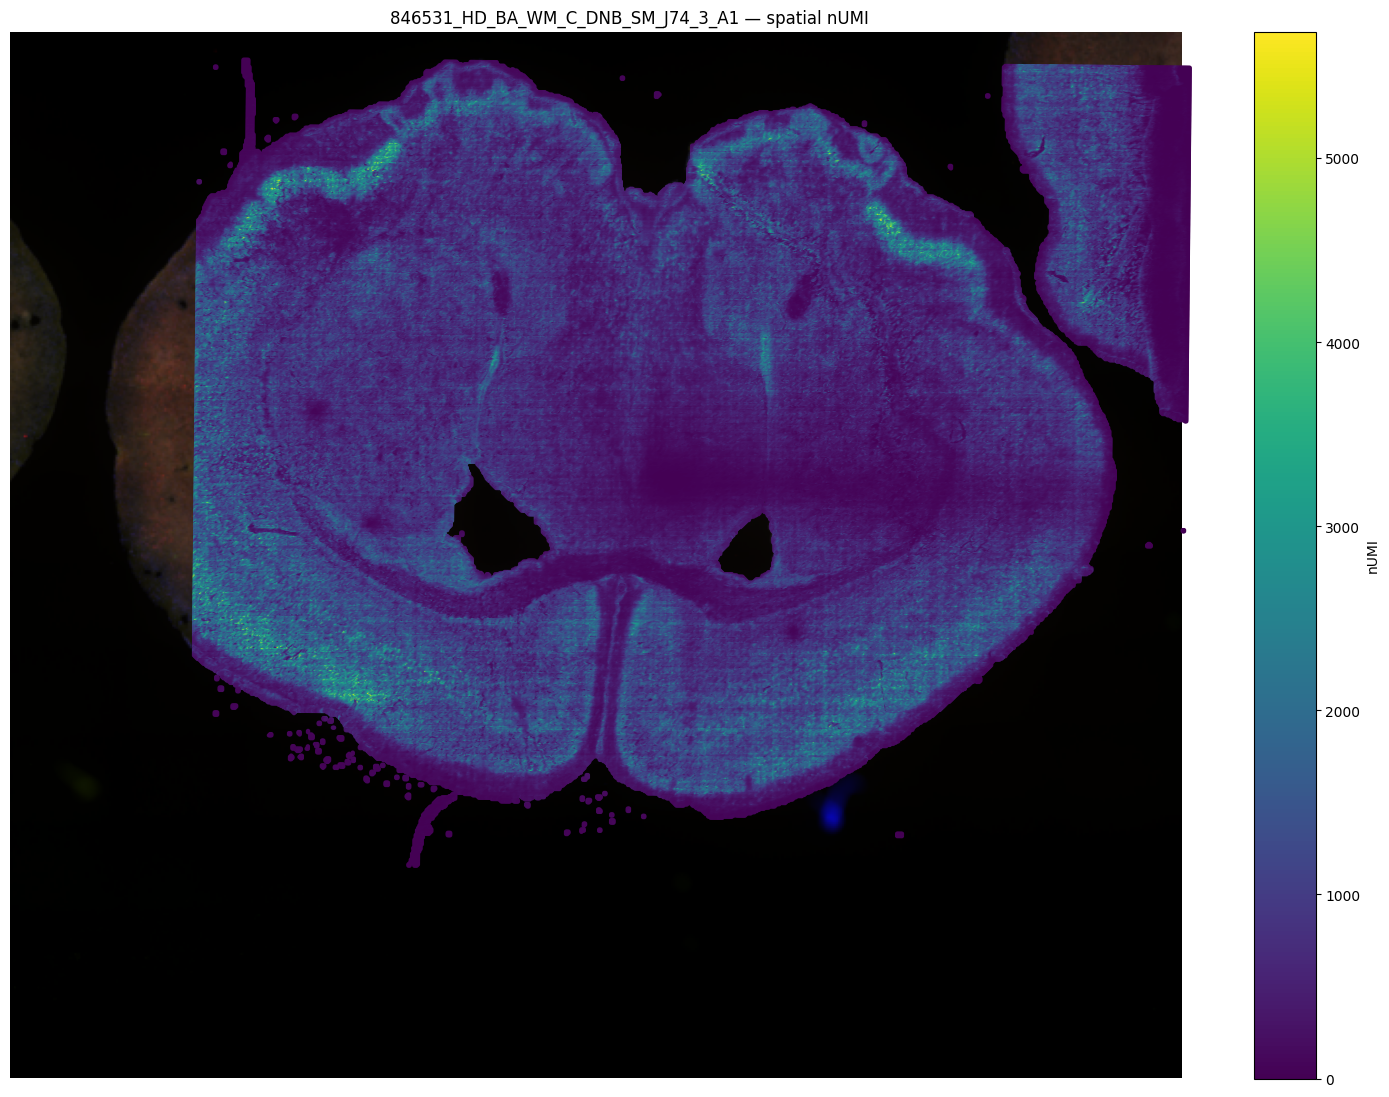

In [6]:
# ── Object summaries ──────────────────────────────────────────────────────────


print(adata)
print(adata.obs.head())
print(adata.obs[["nUMI", "nGene", "pct_MT"]].describe(
    percentiles=[0.25, 0.5, 0.75]).loc[["min", "25%", "50%", "75%", "max"]])
print()

# ── Concatenate (intersection of genes, default join="inner") ─────────────────

#adata_combined = anndata.concat(
#    {"CID44971": adata_CID44971, "CID4535": adata_CID4535},
#    label="sample_id",
#    uns_merge="unique", 
#    index_unique="-"
#)
#adata_combined.obs_names_make_unique()
#print(adata_combined)
#print(adata_combined.obs.head())

# ── Side-by-side spatial nUMI plots ──────────────────────────────────────────

def plot_sample(axes_row, adata):
    img = adata.uns["spatial"][sample_id]["images"]["lowres"]
    lowres_sf = adata.uns["spatial"][sample_id]["scalefactors"]["tissue_lowres_scalef"]
    x = adata.obsm["spatial"][:, 0] * lowres_sf
    y = adata.obsm["spatial"][:, 1] * lowres_sf

    axes_row.imshow(img, origin="upper")
    axes_row.axis("off")
    axes_row.set_title(f"{sample_id} — H&E")

    axes_row.imshow(img, origin="upper", alpha=0.8)
    sc = axes_row.scatter(x, y, c=adata.obs["nUMI"].values,
                              cmap="viridis", s=10, linewidths=0)
    axes_row.axis("off")
    axes_row.set_title(f"{sample_id} — spatial nUMI")

    divider = make_axes_locatable(axes_row)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    plt.colorbar(sc, cax=cax, label="nUMI")

fig, axes = plt.subplots(1, 1, figsize=(14, 12))
plot_sample(axes, adata)
#plot_sample(axes[1], adata)
plt.tight_layout()
plt.show()

# Part I-C: Normalization, Dimensionality Reduction, and Batch Correction

HVGs variable in both samples: 0
HVGs variable in one sample only: 3000


/home/demerson/.conda/envs/spatial/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


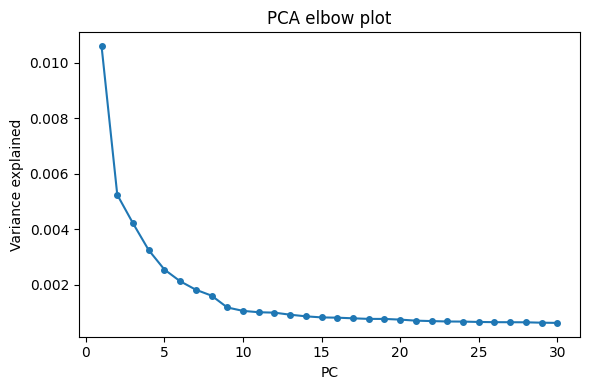

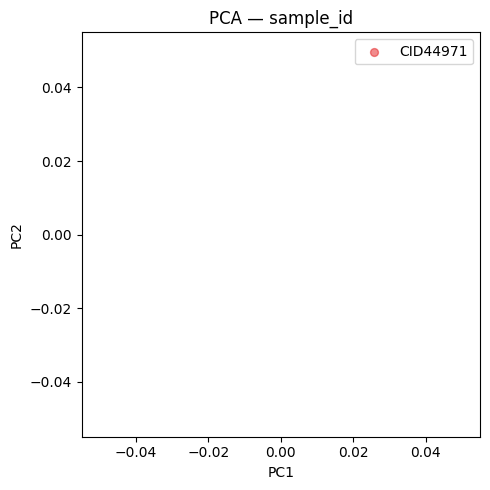

2026-07-23 20:01:31,813 - harmonypy - INFO - Running Harmony
2026-07-23 20:01:31,814 - harmonypy - INFO -   Parameters:
2026-07-23 20:01:31,815 - harmonypy - INFO -     max_iter_harmony: 10
2026-07-23 20:01:31,815 - harmonypy - INFO -     max_iter_kmeans: 4
2026-07-23 20:01:31,816 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-07-23 20:01:31,816 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-07-23 20:01:31,817 - harmonypy - INFO -     nclust: 100
2026-07-23 20:01:31,817 - harmonypy - INFO -     block_size: 0.05
2026-07-23 20:01:31,817 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-07-23 20:01:31,818 - harmonypy - INFO -     theta: [2.]
2026-07-23 20:01:31,819 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-07-23 20:01:31,819 - harmonypy - INFO -     verbose: True
2026-07-23 20:01:31,820 - harmonypy - INFO -     random_state: 42
2026-07-23 20:01:31,820 - harmonypy - INFO -   Data: 30 PCs × 390936 cells
2026-07-23 20:01:31,820 - harmonypy - INFO -   Batc

ValueError: Value passed for key 'X_pca_harmony' is of incorrect shape. Values of obsm must match dimensions ('obs',) of parent. Value had shape (30,) while it should have had (390936,).

In [10]:
import scanpy as sc
import harmonypy as hm
import matplotlib.pyplot as plt

# ── Normalization ─────────────────────────────────────────────────────────────

# Filter low-quality spots
sc.pp.filter_cells(adata, min_counts=500)
sc.pp.filter_genes(adata, min_cells=10)

# Stash raw counts
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# ── HVG selection ─────────────────────────────────────────────────────────────

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=3000,
    flavor="seurat",
    batch_key="sample_id"
)

print(f"HVGs variable in one sample only: {adata.var['highly_variable_nbatches'].eq(1).sum()}")

# ── PCA ───────────────────────────────────────────────────────────────────────

sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=30, use_highly_variable=True, random_state=42)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, 31), adata.uns["pca"]["variance_ratio"], "o-", markersize=4)
ax.set_xlabel("PC")
ax.set_ylabel("Variance explained")
ax.set_title("PCA elbow plot")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
for sid, color in zip(["CID44971"], ["#E41A1C"]):
    mask = adata.obs["sample_id"] == sid
    ax.scatter(
        adata.obsm["X_pca"][mask, 0],
        adata.obsm["X_pca"][mask, 1],
        c=color, s=2, alpha=0.5, label=sid
    )
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(markerscale=4)
ax.set_title("PCA — sample_id")
plt.tight_layout()
plt.show()

# ── Harmony batch correction ──────────────────────────────────────────────────

ho = hm.run_harmony(
    adata.obsm["X_pca"],
    adata.obs,
    vars_use="sample_id",
    random_state=42
)
adata.obsm["X_pca_harmony"] = ho.Z_corr.T

# ── KNN + UMAP ────────────────────────────────────────────────────────────────

sc.pp.neighbors(adata, use_rep="X_pca_harmony", random_state=42)
sc.tl.umap(adata, random_state=42)

fig, ax = plt.subplots(figsize=(5, 5))
for sid, color in zip(["CID44971"], ["#E41A1C"]):
    mask = adata_combined.obs["sample_id"] == sid
    ax.scatter(
        adata_combined.obsm["X_umap"][mask, 0],
        adata_combined.obsm["X_umap"][mask, 1],
        c=color, s=2, alpha=0.5, label=sid
    )
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(markerscale=4)
ax.set_title("UMAP — sample_id")
plt.tight_layout()
plt.show()

# Part I-D: Clustering and Spatial Maps

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Leiden clustering ─────────────────────────────────────────────────────────

sc.tl.leiden(adata_combined, resolution=0.3, key_added="leiden_coarse", random_state=42)
sc.tl.leiden(adata_combined, resolution=0.8, key_added="leiden_fine", random_state=42)

n_coarse = adata_combined.obs["leiden_coarse"].nunique()
n_fine = adata_combined.obs["leiden_fine"].nunique()
print(f"Coarse resolution (0.3): {n_coarse} clusters")
print(f"Fine resolution (0.8):   {n_fine} clusters")

# ── UMAP colored by cluster ───────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, key, title in zip(axes,
                           ["leiden_coarse", "leiden_fine"],
                           [f"Leiden r=0.3 ({n_coarse} clusters)",
                            f"Leiden r=0.8 ({n_fine} clusters)"]):
    sc.pl.umap(adata_combined, color=key, ax=ax, show=False, title=title, frameon=False)
plt.tight_layout()
plt.show()

# ── Use coarse resolution downstream ─────────────────────────────────────────

cluster_key = "leiden_coarse"

# ── Spatial cluster maps ──────────────────────────────────────────────────────

sample_ids = ["CID44971", "CID4535"]
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

clusters = adata_combined.obs[cluster_key].cat.categories
palette = dict(zip(clusters, sc.pl.palettes.default_20[:len(clusters)]))

for row, sample_id in enumerate(sample_ids):
    adata_sub = adata_combined[adata_combined.obs["sample_id"] == sample_id]
    img = adata_sub.uns["spatial"][sample_id]["images"]["lowres"]
    lowres_sf = adata_sub.uns["spatial"][sample_id]["scalefactors"]["tissue_lowres_scalef"]
    x = adata_sub.obsm["spatial"][:, 0] * lowres_sf
    y = adata_sub.obsm["spatial"][:, 1] * lowres_sf

    axes[row, 0].imshow(img, origin="upper")
    axes[row, 0].axis("off")
    axes[row, 0].set_title(f"{sample_id} — H&E")

    axes[row, 1].imshow(img, origin="upper", alpha=0.5)
    for clust in clusters:
        mask = adata_sub.obs[cluster_key] == clust
        axes[row, 1].scatter(x[mask], y[mask], c=palette[clust],
                              s=10, alpha=0.8, linewidths=0, label=clust)
    axes[row, 1].axis("off")
    axes[row, 1].set_title(f"{sample_id} — Leiden clusters")
    axes[row, 1].legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left",
                         fontsize=7, title="Cluster")

plt.tight_layout()
plt.show()

# ── Stacked bar chart ─────────────────────────────────────────────────────────

obs = adata_combined.obs[[cluster_key, "sample_id"]].copy()
counts = obs.groupby([cluster_key, "sample_id"], observed=False).size().unstack(fill_value=0)
props = counts.div(counts.sum(axis=1), axis=0)

props.plot(kind="bar", stacked=True, figsize=(10, 4), color=["#E41A1C", "#377EB8"])
plt.xlabel("Leiden cluster")
plt.ylabel("Proportion of spots")
plt.title("Sample composition per cluster")
plt.xticks(rotation=0)
plt.legend(title="sample_id", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()